# T1 Vision por computador Jose Quimi

Este archivo es para realizar los procesos paso a paso, posteriormente se arma un archivo main.py que ejecuta el codigo compelto por si solo

In [1]:
# imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
# imgs paths
img_path = os.path.join("..", "imgs")
# print(os.path.join(img_path, "img1.jpg"))
img1, img2, img3, img4 = [cv2.imread(os.path.join(img_path, f"img{i}.jpg")) for i in range(1, 5)]
N, M = img1.shape[:2] # eliminando el canal de color

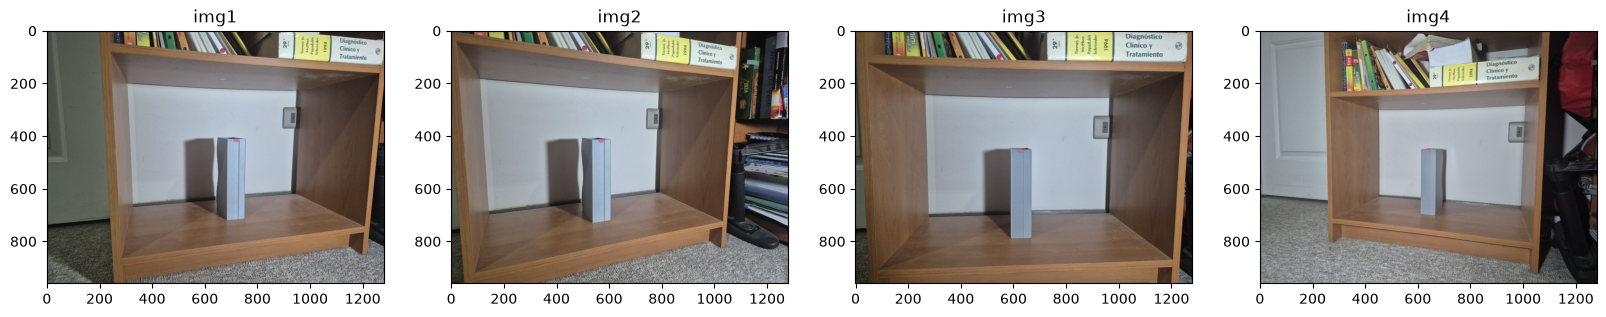

Shape = (960, 1280, 3)


In [3]:
# show imgs
fig, axs = plt.subplots(1, 4, figsize=(20, 10))
axs[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
axs[0].set_title('img1')

axs[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), cmap='gray')
axs[1].set_title('img2')

axs[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB), cmap='gray')
axs[2].set_title('img3')

axs[3].imshow(cv2.cvtColor(img4, cv2.COLOR_BGR2RGB), cmap='gray')
axs[3].set_title('img4')
plt.show()
print(f"Shape = {img1.shape}")

Utilizando la imagen 3 como imagen explicativa, los puntos se disponen en el siguiente orden, siendo el punto 1 el punto de origen, ademas se indica el punto objetivo.

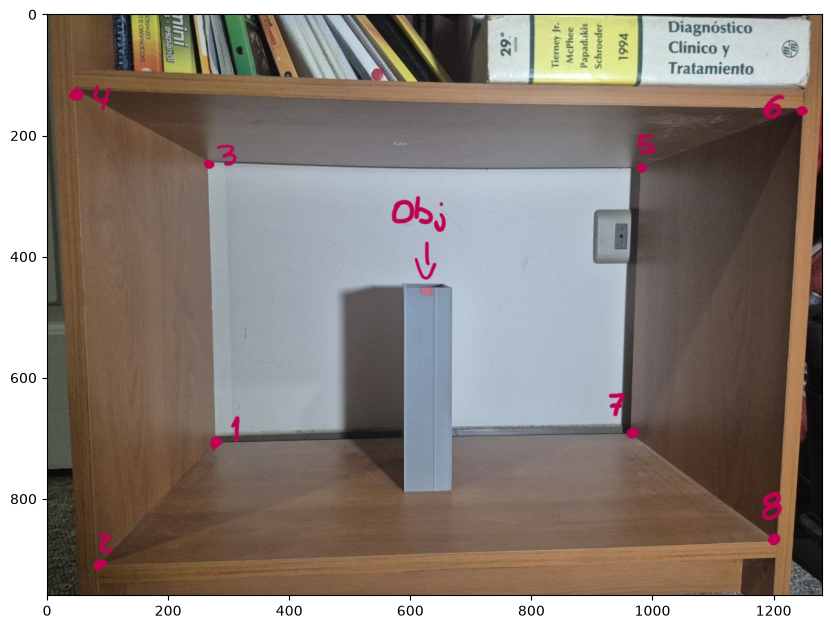

In [4]:
img_ej_path = os.path.join("..", "imgs/img_explicacion.jpg")
img_ej = cv2.imread(img_ej_path)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_ej, cv2.COLOR_BGR2RGB), cmap='gray')
plt.show()

#### Obtener la matriz de calibracion de la imagen 1 y 2

In [5]:
# definir M, los puntos reales con el punto 1 como el origen, todo en milimetros
M = np.array([
    [0.0,  0.0,   0.0,   0.0,   570.0, 570.0, 570.0, 570.0],
    [0.0,  294.0, 0.0,   294.0, 0.0,   294.0, 0.0,   294.0],
    [0.0,  0.0,   369.0, 369.0, 369.0, 369.0, 0.0,   0.0],
    [1.0,  1.0,   1.0,   1.0,   1.0,   1.0,   1.0,   1.0]
])
# lista de puntos
puntos_list = []

##### Funciones

In [6]:
# Funcion de calibracion de la camara
def calibracion(M,w):

  # Escribe código aquí
  n = M.shape[1]

  X_v = []

  for i in range(n):
    X, Y, Z = M[0, i], M[1, i], M[2, i]
    u, v = w[0, i], w[1, i]

    x_1 = np.array([X, Y, Z, 1, 0, 0, 0, 0, -u*X, -u*Y, -u*Z, -u])
    x_2 = np.array([0, 0, 0, 0, X, Y, Z, 1, -v*X, -v*Y, -v*Z, -v])

    # Apilar
    X_vi = np.vstack([x_1, x_2])

    if i == 0:
      X_v = X_vi
    else:
      X_v = np.vstack([X_v, X_vi])

  U, S, VT = np.linalg.svd(X_v)
  a = VT[-1,:]
  P = a.reshape(3, 4)

  return P
# Callback para mouse
def mouse_callback(event, x, y, flags, param):
    puntos_list, img = param
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"Clicked at: ({x}, {y})")
        puntos_list.append((x, y))
        
        cv2.circle(img, (x, y), 5, (0, 255, 0), -1)
        cv2.putText(img, f"{len(puntos_list)}", (x + 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    elif event == cv2.EVENT_RBUTTONDOWN:
        if puntos_list:
            punto_removido = puntos_list.pop()
            print(f"Punto removido {punto_removido}")
        img[:] = img.copy()
        
        for index, (px, py) in enumerate(puntos_list):
            cv2.circle(img, (px, py), 5, (0, 255, 0), -1)
            cv2.putText(img, f"{index + 1}", (px + 10, py - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

##### Obtener m1 de la imagen 1

In [7]:
# levantar imagen y mostrarla en una ventana para obtener los puntos de las esquinas
display_img = img1.copy()
flag = True
cv2.namedWindow("Seleccionar puntos")
cv2.resizeWindow("Seleccionar puntos", img1.shape[1]-200, img1.shape[0]-200)
cv2.setMouseCallback("Seleccionar puntos", mouse_callback, param=(puntos_list, display_img))

while flag:
    cv2.imshow("Seleccionar puntos", display_img)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q'):
        flag = False
    elif key == ord('r'):
        puntos_list.clear()
        display_img = img1.copy()
        print("Puntos reiniciados")
cv2.destroyAllWindows()
print(f"Puntos seleccionados: {puntos_list}")


Clicked at: (330, 668)
Clicked at: (286, 863)
Clicked at: (307, 197)
Clicked at: (245, 83)
Clicked at: (964, 230)
Clicked at: (1264, 163)
Punto removido (1264, 163)
Clicked at: (1264, 162)
Clicked at: (945, 619)
Clicked at: (1208, 743)
Puntos seleccionados: [(330, 668), (286, 863), (307, 197), (245, 83), (964, 230), (1264, 162), (945, 619), (1208, 743)]


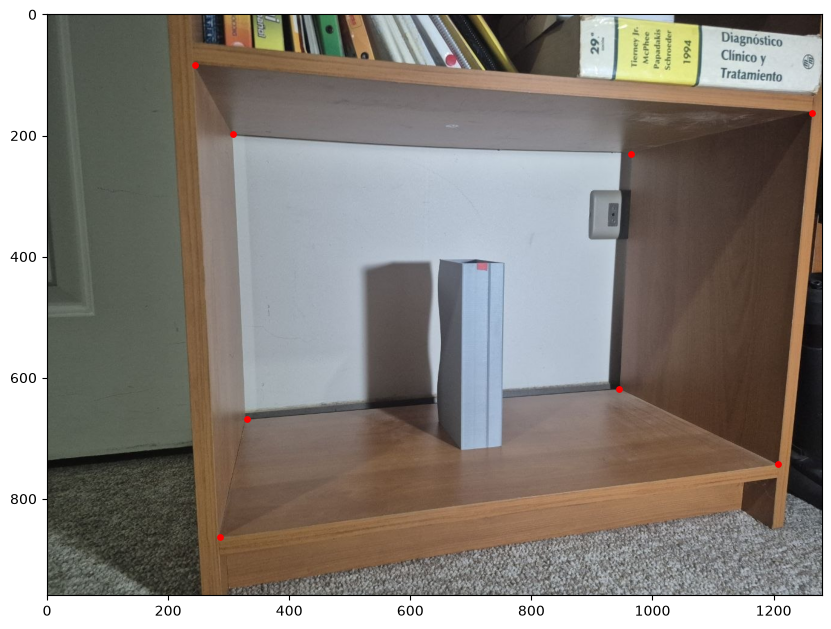

Los puntos que representan la caja son: [(330, 668), (286, 863), (307, 197), (245, 83), (964, 230), (1264, 162), (945, 619), (1208, 743)]


In [8]:
# Obtener m1 desde la imagen 1
# puntos = [(327, 670), (284, 863), (245, 80), (305, 198), (966, 225), (1262, 161), (946, 618), (1205, 743)]
# esto hay que cambiarlo por seleccion por medio de mouse en una ventana
x, y = zip(*puntos_list)

plt.figure(figsize=(10, 10))

plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
plt.scatter(x, y, color='red', s=15)
plt.show()
print(f"Los puntos que representan la caja son: {puntos_list}")

In [9]:
# obtener matriz de proyeccion P

# Definir los vectores de m1
x_p = np.array([p[0] for p in puntos_list])
y_p = np.array([p[1] for p in puntos_list])
print(f"x_p = {x_p}")
print(f"y_p = {y_p}")

m1 = np.vstack((x_p, y_p, np.ones(len(x_p))))
print(m1)

P = calibracion(M, m1)
print(f"Matriz de proyeccion P = \n{P}")


x_p = [ 330  286  307  245  964 1264  945 1208]
y_p = [668 863 197  83 230 162 619 743]
[[3.300e+02 2.860e+02 3.070e+02 2.450e+02 9.640e+02 1.264e+03 9.450e+02
  1.208e+03]
 [6.680e+02 8.630e+02 1.970e+02 8.300e+01 2.300e+02 1.620e+02 6.190e+02
  7.430e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[-1.89809546e-03  7.02163040e-04  1.58107559e-04 -4.42434316e-01]
 [-1.78734910e-04  6.38688402e-04  1.75996406e-03 -8.96795636e-01]
 [-4.73285691e-07  1.77756202e-06  2.53980050e-07 -1.34367614e-03]]


In [122]:
# aislar matriz K desde P

# aislar la submatriz de 3x3 superior izquierda de P
subM = P[:, :3]
print(f"Submatriz de 3x3 superior izquierda de P: \n{subM}")

# descomposicion RQ de la submatriz
J = np.fliplr(np.eye(3))
subM_temp = J @ subM.T @ J

Q_qr, R_qr = np.linalg.qr(subM_temp)

# invertir la descomposicion RQ para obtener K y R
K = J @ R_qr.T @ J
R = J @ Q_qr.T @ J
# asegurar que sea diagonal positvo
signos = np.sign(np.diag(K))
signos[signos == 0] = 1  # evitar ceros
diag = np.diag(signos)
K = K @ diag
R = diag @ R

#normalizar K
K = K / K[2, 2]
print(f"Matriz K: \n{K}")
print(f"Matriz R: \n{R}")
# Como es la misma camara y el centro optico es el mismo K1 = K2
# https://www.datacamp.com/es/tutorial/singular-value-decomposition


Submatriz de 3x3 superior izquierda de P: 
[[-1.89809546e-03  7.02163040e-04  1.58107559e-04]
 [-1.78734910e-04  6.38688402e-04  1.75996406e-03]
 [-4.73285691e-07  1.77756202e-06  2.53980050e-07]]
Matriz K: 
[[890.45713564   2.91607901 634.13249875]
 [  0.         890.03418866 483.40619491]
 [  0.           0.           1.        ]]
Matriz R: 
[[-0.96649994 -0.25661757 -0.00502772]
 [ 0.03028563 -0.13347283  0.99058961]
 [-0.25487377  0.95725254  0.13677331]]


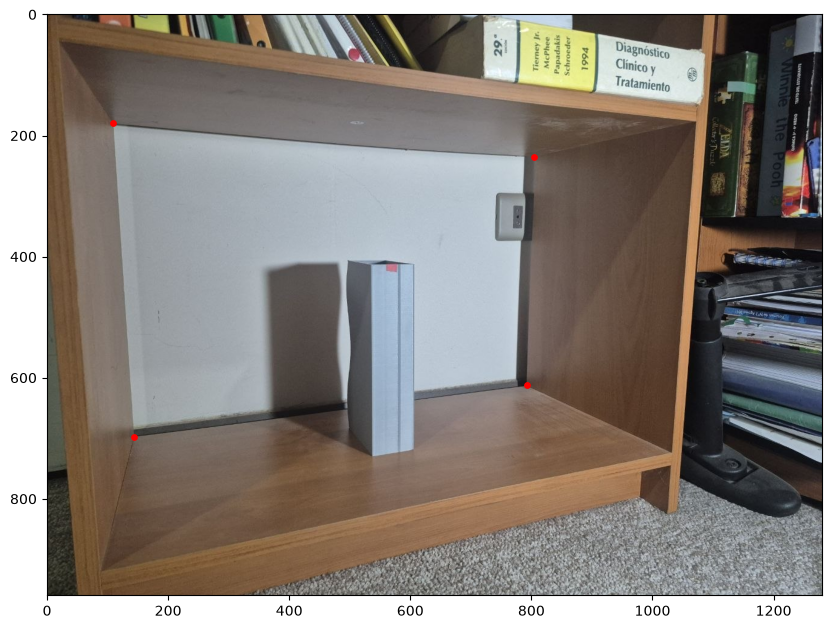

Los puntos ancla que representan la parte trasera de lacaja son: [(143, 698), (109, 180), (805, 235), (792, 612)]
m_ancla = [[143. 109. 805. 792.]
 [698. 180. 235. 612.]
 [  1.   1.   1.   1.]]


In [115]:
# definir 4 puntos ancla de la imagen 2
puntos_ancla = [(143, 698), (109, 180), (805, 235), (792, 612)]

x, y = zip(*puntos_ancla)

plt.figure(figsize=(10, 10))

plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.scatter(x, y, color='red', s=15)
plt.show()
print(f"Los puntos ancla que representan la parte trasera de lacaja son: {puntos_ancla}")
x_ancla = np.array([p[0] for p in puntos_ancla])
y_ancla = np.array([p[1] for p in puntos_ancla])
m_ancla = np.vstack((x_ancla, y_ancla, np.ones(len(x_ancla))))
print(f"m_ancla = {m_ancla}")

#### Realizar homografia desde img 1 a img2

In [116]:
# Extraido de E02
def homography(X,H):
  N, M, C = X.shape
  Hinv  = np.linalg.inv(H)
  Xp    = np.zeros((N,M,C),np.uint8)

  m = np.ones((N*M,3))
  t = 0
  for i in range(N):
    for j in range(M):
      m[t,0:2] = [j,i]
      t = t+1

  mph = np.dot(Hinv,m.T)  # Transformation m to mp
  mp  = np.divide(mph[0:2,:],mph[2,:])
  mpf = np.trunc(mp).astype(int) #np.fix is deprecated

  ip = mpf[1,:]
  jp = mpf[0,:]
  
  ktj = np.logical_and(jp >= 0,  jp<M)
  kti = np.logical_and(ip >=0, ip < N)
  kt  = np.logical_and(kti, ktj)

  t = 0
  for i in range(N):
    for j in range(M):
      if kt[t]:
        Xp[i,j] = X[ip[t],jp[t]]
      t = t+1
  return Xp

def homography_matrix(m,mp):
  (x ,y ) = m
  (xp,yp) = mp
  n       = len(x)
  A       = np.zeros((2*n,9))
  for i in range(n):
    j = i*2
    A[j  ,:] = [x[i], y[i], 1,     0,     0, 0, -x[i]*xp[i], -y[i]*xp[i], -xp[i]]
    A[j+1,:] = [  0  ,   0  , 0, x[i], y[i], 1, -x[i]*yp[i], -y[i]*yp[i], -yp[i]]
  [U,S,V] = np.linalg.svd(A)
  h       = V[-1,:]
  H       = np.vstack([h[0:3], h[3:6], h[6:9]])
  return H
        

In [ ]:
# Aplicar parametros intrinsecos a los puntos m1 y m ancla
m1_k_t = np.dot(np.linalg.inv(K), m1)
m_ancla_k_t = np.dot(np.linalg.inv(K), m_ancla)

# dividir por la tercera componenete
m1_k = m1_k_t / m1_k_t[2, :]
m_ancla_k = m_ancla_k_t / m_ancla_k_t[2, :]

print(f"m1_k = {m1_k}")
print(f"m_ancla_k = {m_ancla_k}")

x1_k, y1_k = m1_k[0, 0:4], m1_k[1, 0:4]
x_ancla_k, y_ancla_k = m_ancla_k[0, :], m_ancla_k[1, :]
print(f"\nx1_k = {x1_k}")
print(f"y1_k = {y1_k}")
print(f"x_ancla_k = {x_ancla_k}")
print(f"y_ancla_k = {y_ancla_k}")
# obtener H_norm, ingresando los puntos normalizados, 
H_n = homography_matrix((x1_k, y1_k), (x_ancla_k, y_ancla_k))
print(f"\nH_norm = {H_n}")

# descomponer H_norm para obtener la matriz de rotacion
# https://www.datacamp.com/es/tutorial/singular-value-decomposition

U, S, Vt = np.linalg.svd(H_n)
R = U @ Vt
print(f"\nR = {R}")

H_12 = K @ R @ np.linalg.inv(K)
print(f"\nLa matriz de homografia H_12 = {H_12}")


m1_k = [[-0.34222568 -0.39235599 -0.3663221  -0.4355298   0.37137976  0.70853556
   0.34861111  0.64350877]
 [ 0.2074008   0.42649351 -0.32179235 -0.44987732 -0.28471512 -0.36111668
   0.15234674  0.29166723]
 [ 1.          1.          1.          1.          1.          1.
   1.          1.        ]]
m_ancla_k = [[-0.55234055 -0.58861725  0.19280139  0.176815  ]
 [ 0.24110737 -0.34089274 -0.27909736  0.14448187]
 [ 1.          1.          1.          1.        ]]

x1_k = [-0.34222568 -0.39235599 -0.3663221  -0.4355298 ]
y1_k = [ 0.2074008   0.42649351 -0.32179235 -0.44987732]
x_ancla_k = [-0.55234055 -0.58861725  0.19280139  0.176815  ]
y_ancla_k = [ 0.24110737 -0.34089274 -0.27909736  0.14448187]

H_norm = [[ 0.23181121 -0.04583817  0.05397354]
 [ 0.74123657 -0.04928945  0.27911214]
 [ 0.46572418  0.25679001  0.16924675]]

R = [[ 0.56570232 -0.23168825 -0.79139209]
 [ 0.6839295  -0.40432628  0.6072567 ]
 [ 0.46067486  0.88478292  0.07026989]]

La matriz de homografiaH_12 = [[ 8.96008

In [119]:
# obtener m2 usando la matriz de homografia y m1
m2_temp = H_12 @ m1
print(N, M)
print(f"\nm2 temporal = {m2_temp}")
m2 = m2_temp / m2_temp[-1, :]
print(f"\nEstimacion de m2 = {m2}")

960 [[  0.   0.   0.   0. 570. 570. 570. 570.]
 [  0. 294.   0. 294.   0. 294.   0. 294.]
 [  0.   0. 369. 369. 369. 369.   0.   0.]
 [  1.   1.   1.   1.   1.   1.   1.   1.]]

m2 temporal = [[-8.58083432e+02 -8.20612989e+02 -1.06442216e+03 -1.16492856e+03
  -4.62731754e+02 -2.20743871e+02 -3.26360628e+02 -4.18132407e+01]
 [ 3.03988180e+02  2.77173570e+02  2.48050800e+02  1.81820598e+02
   8.63901757e+02  1.13903423e+03  8.74624195e+02  1.12925840e+03]
 [ 9.61198097e-02  2.66875521e-01 -3.83201870e-01 -5.28411511e-01
  -1.05558721e-02  7.71645377e-02  3.65660053e-01  6.24780385e-01]]

Estimacion de m2 = [[-8.92722775e+03 -3.07489044e+03  2.77770606e+03  2.20458588e+03
   4.38364304e+04 -2.86069065e+03 -8.92524697e+02 -6.69247013e+01]
 [ 3.16259656e+03  1.03858746e+03 -6.47311037e+02 -3.44089019e+02
  -8.18408698e+04  1.47611100e+04  2.39190523e+03  1.80744855e+03]
 [ 1.00000000e+00  1.00000000e+00  1.00000000e+00  1.00000000e+00
   1.00000000e+00  1.00000000e+00  1.00000000e+00  1.000

(960, 1280, 3)

H_12 = [[ 8.96008275e-01  3.94332347e-01 -1.41718017e+03]
 [ 9.33693137e-01  7.31686575e-02 -5.30072189e+01]
 [ 5.17346478e-04  9.92404906e-04 -7.37531005e-01]]
Imagen izquierda: Transformada                       | Imagen derecha: Original


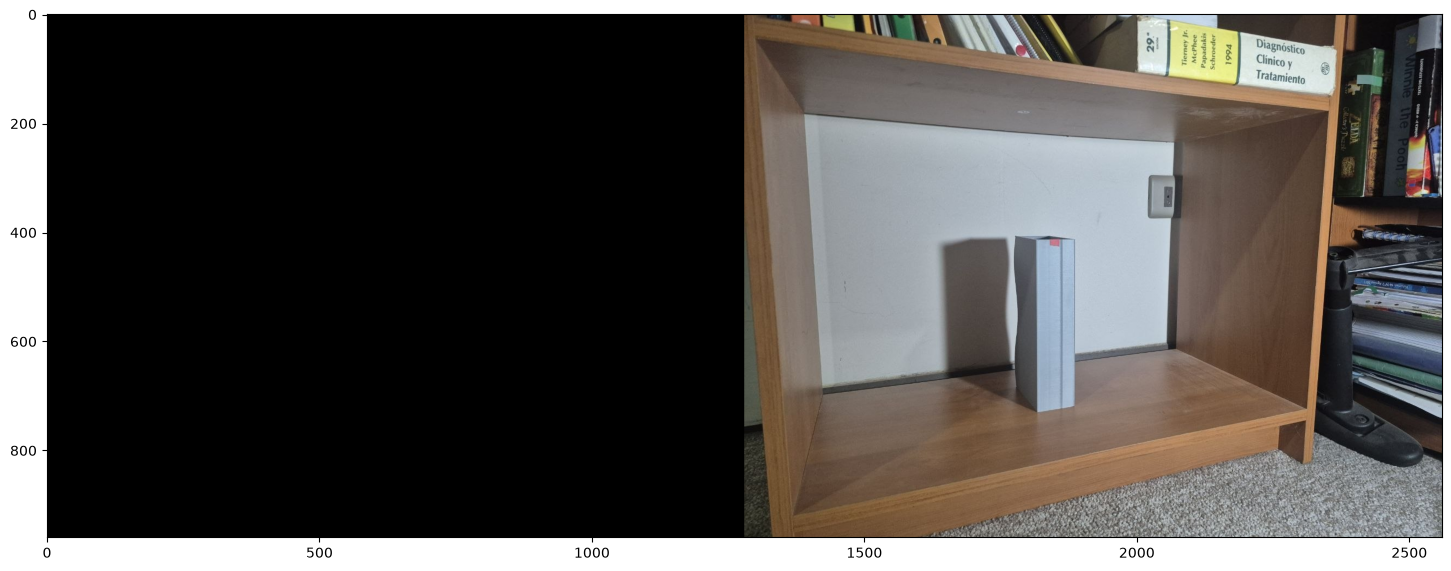

In [125]:
# comprobar homografia realizando la transformacion de img1 con la matriz de homografia H_12
# H_12_inv = np.linalg.inv(H_12)
print(img1.shape)
print(f"\nH_12 = {H_12}")
img1_transf = homography(img1, H_12)
Z = np.concatenate((img1_transf, img2), axis=1)
print('Imagen izquierda: Transformada                       | Imagen derecha: Original')
plt.figure(figsize=(18,24))
plt.imshow(cv2.cvtColor(Z, cv2.COLOR_BGR2RGB))
plt.show()

In [121]:
print(img1_transf.shape)
print(img1_transf.mean(axis=(0, 1)))
print(np.count_nonzero(img1_transf))

(960, 1280, 3)
[0. 0. 0.]
0
